# Limpeza e pré-modelagem dos dados de crédito

## Estratégia de divisão entre treino e teste

A análise exploratória encontrou perfis com valores idênticos nas variáveis de entrada, incluindo 37 perfis que aparecem com as duas classes do alvo.

Na divisão dos dados, vamos agrupar os registros pelas dez variáveis de entrada e manter cada grupo inteiro em treino ou em teste. Depois, vamos conferir se a proporção de casos de atraso grave ficou próxima nos dois conjuntos.

As decisões que aprendem parâmetros dos dados, como medianas de imputação e limites por percentil, serão ajustadas exclusivamente no treino.# Limpeza e pré-modelagem dos dados de crédito

### Carregamento e agrupamento dos perfis

O CSV original passa pelo Raw Gate antes da divisão. Cada perfil é definido pelos valores das dez variáveis de entrada, incluindo o padrão de ausências. A numeração `Unnamed: 0` e o desfecho `SeriousDlqin2yrs` ficam fora da definição do perfil.

Os 150.000 registros formam 149.354 perfis distintos. O identificador de grupo serve para manter juntos os registros com os mesmos valores de entrada.

In [1]:
import sys
from pathlib import Path

import pandas as pd

raiz_projeto = Path.cwd()
if raiz_projeto.name == "notebooks":
    raiz_projeto = raiz_projeto.parent

if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

from src.schema_validator import RAW_SCHEMA

caminho_csv = raiz_projeto / "data" / "raw" / "cs-training.csv"
dados_brutos = RAW_SCHEMA.validate(pd.read_csv(caminho_csv), lazy=True)

alvo = dados_brutos["SeriousDlqin2yrs"]
entradas_brutas = dados_brutos.drop(columns=["Unnamed: 0", "SeriousDlqin2yrs"])

grupos_perfil = entradas_brutas.groupby(
    entradas_brutas.columns.tolist(),
    dropna=False,
    sort=False,
).ngroup()

print(f"Registros validados: {len(dados_brutos)}")
print(f"Variáveis de entrada: {entradas_brutas.shape[1]}")
print(f"Perfis distintos: {grupos_perfil.nunique()}")

Registros validados: 150000
Variáveis de entrada: 10
Perfis distintos: 149354


In [2]:
from sklearn.model_selection import StratifiedGroupKFold

divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

indices_treino, indices_teste = next(
    divisor.split(entradas_brutas, alvo, groups=grupos_perfil)
)

dados_treino = dados_brutos.iloc[indices_treino].copy()
dados_teste = dados_brutos.iloc[indices_teste].copy()

grupos_treino = set(grupos_perfil.iloc[indices_treino])
grupos_teste = set(grupos_perfil.iloc[indices_teste])
grupos_em_comum = grupos_treino & grupos_teste

print(f"Perfis presentes nos dois conjuntos: {len(grupos_em_comum)}")
assert not grupos_em_comum, "Há perfis compartilhados entre treino e teste."

resumo_divisao = pd.DataFrame({
    "registros": [len(dados_treino), len(dados_teste)],
    "atrasos_graves": [
        dados_treino["SeriousDlqin2yrs"].sum(),
        dados_teste["SeriousDlqin2yrs"].sum(),
    ],
}, index=["Treino", "Teste"])

resumo_divisao["atraso_grave_pct"] = (
    resumo_divisao["atrasos_graves"] / resumo_divisao["registros"] * 100
).round(2)

resumo_divisao

Perfis presentes nos dois conjuntos: 0


,registros,atrasos_graves,atraso_grave_pct
Treino,120001,8021,6.68
Teste,29999,2005,6.68


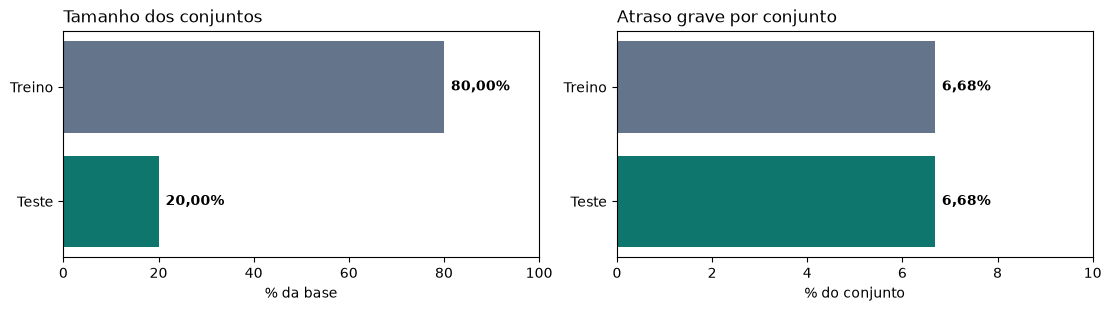

In [3]:
import matplotlib.pyplot as plt

percentual_da_base = (
    resumo_divisao["registros"] / resumo_divisao["registros"].sum() * 100
)
percentual_atraso_grave = (
    resumo_divisao["atrasos_graves"] / resumo_divisao["registros"] * 100
)

fig, (ax_tamanho, ax_alvo) = plt.subplots(
    1, 2, figsize=(11, 3), layout="constrained"
)

paineis = [
    (ax_tamanho, percentual_da_base, "Tamanho dos conjuntos", "% da base", 100),
    (ax_alvo, percentual_atraso_grave, "Atraso grave por conjunto", "% do conjunto", 10),
]

for ax, valores, titulo, rotulo_x, limite in paineis:
    barras = ax.barh(valores.index, valores, color=["#64748b", "#0f766e"])
    ax.bar_label(
        barras,
        labels=[f"{valor:.2f}%".replace(".", ",") for valor in valores],
        padding=5,
        fontweight="bold",
    )
    ax.set_xlim(0, limite)
    ax.set_xlabel(rotulo_x)
    ax.set_title(titulo, loc="left")
    ax.invert_yaxis()

plt.show()

### Resultado da divisão

Usamos a primeira partição de uma divisão estratificada em cinco partes, com agrupamento por perfil e semente 42. As outras quatro partes formam o treino.

| Conjunto | Registros | Casos de atraso grave | Percentual |
| --- | ---: | ---: | ---: |
| Treino | 120.001 | 8.021 | 6,68% |
| Teste | 29.999 | 2.005 | 6,68% |

A verificação encontrou zero perfis compartilhados entre treino e teste. Esses conjuntos serão a referência para a avaliação dos modelos.

## Limpeza das variáveis de entrada

### Tratamento da idade zero

A EDA encontrou um registro com `age = 0`, valor incompatível com a idade de um tomador de crédito. Vamos marcá-lo como ausente nas cópias de treino e teste. As idades acima de 100 anos serão mantidas porque a triagem identificou sua raridade e elas são possíveis.

A marcação de idade zero segue a mesma regra nos dois conjuntos. A mediana usada para preencher a idade ausente será calculada apenas no treino e aplicada aos dois conjuntos.

In [4]:
X_treino = entradas_brutas.iloc[indices_treino].copy()
X_teste = entradas_brutas.iloc[indices_teste].copy()

for nome, entradas in [("Treino", X_treino), ("Teste", X_teste)]:
    idade_zero = entradas["age"].eq(0)
    entradas["age"] = entradas["age"].mask(idade_zero)

    print(f"{nome}: {idade_zero.sum()} idade(s) zero marcada(s) como ausente(s)")

Treino: 0 idade(s) zero marcada(s) como ausente(s)
Teste: 1 idade(s) zero marcada(s) como ausente(s)


#### Preenchimento com a mediana do treino

Calculamos a mediana de `age` usando apenas o conjunto de treino. Aplicamos esse mesmo valor aos campos de idade ausentes nos dois conjuntos. A contagem antes e depois mostra onde o preenchimento foi aplicado.

In [5]:
mediana_idade = X_treino["age"].median()
print(f"Mediana da idade no treino: {mediana_idade:g} anos")

for nome, entradas in [("Treino", X_treino), ("Teste", X_teste)]:
    ausentes_antes = entradas["age"].isna().sum()
    entradas["age"] = entradas["age"].fillna(mediana_idade)
    ausentes_depois = entradas["age"].isna().sum()

    print(f"{nome}: {ausentes_antes} → {ausentes_depois} idades ausentes")

Mediana da idade no treino: 52 anos
Treino: 0 → 0 idades ausentes
Teste: 1 → 0 idades ausentes


### Tratamento dos valores 96 e 98 no histórico de atrasos

Na EDA, 269 registros apresentaram o mesmo valor (`96` ou `98`) nas três contagens de atraso. A presença desses registros alterou bastante a correlação de Pearson entre as colunas.

Como o significado desses valores permanece em aberto, a regra proposta é marcar as ocorrências de `96` e `98` como ausentes nas contagens e criar o indicador `tem_atraso_96_98`. Assim, o pipeline preserva a informação de que o registro chegou com esse padrão.

In [6]:
colunas_atraso = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]

for nome, origem, entradas in [
    ("Treino", dados_treino, X_treino),
    ("Teste", dados_teste, X_teste),
]:
    atrasos_brutos = origem[colunas_atraso]
    valores_sinalizados = atrasos_brutos.isin([96, 98])

    entradas[colunas_atraso] = atrasos_brutos.mask(valores_sinalizados)
    entradas["tem_atraso_96_98"] = valores_sinalizados.any(axis=1).astype("int8")

    print(
        f"{nome}: {entradas['tem_atraso_96_98'].sum()} registros sinalizados "
        f"e {valores_sinalizados.sum().sum()} valores marcados como ausentes."
    )

Treino: 212 registros sinalizados e 636 valores marcados como ausentes.
Teste: 57 registros sinalizados e 171 valores marcados como ausentes.


#### Preenchimento das contagens de atraso

Calculamos uma mediana para cada faixa de atraso usando apenas as contagens válidas do treino. Aplicamos essas mesmas medianas para preencher as lacunas no treino e no teste.

O indicador `tem_atraso_96_98` preserva a informação de que o registro continha um valor sinalizado antes do preenchimento.

In [7]:
atrasos_treino_brutos = dados_treino[colunas_atraso]
atrasos_treino_validos = atrasos_treino_brutos.mask(
    atrasos_treino_brutos.isin([96, 98])
)
medianas_atraso = atrasos_treino_validos.median()

for nome, entradas in [("Treino", X_treino), ("Teste", X_teste)]:
    ausentes_antes = entradas[colunas_atraso].isna().sum().sum()
    entradas[colunas_atraso] = entradas[colunas_atraso].fillna(medianas_atraso)
    ausentes_depois = entradas[colunas_atraso].isna().sum().sum()

    print(f"{nome}: {ausentes_antes} → {ausentes_depois} contagens ausentes")

medianas_atraso.to_frame("mediana_do_treino")

Treino: 636 → 0 contagens ausentes
Teste: 171 → 0 contagens ausentes


,mediana_do_treino
NumberOfTime30-59DaysPastDueNotWorse,0.0
NumberOfTime60-89DaysPastDueNotWorse,0.0
NumberOfTimes90DaysLate,0.0


#### Verificação do tratamento das contagens de atraso

Comparamos quantas células contêm `96` ou `98` antes e depois do tratamento, separando treino e teste. Também verificamos se restaram valores ausentes nas três contagens.

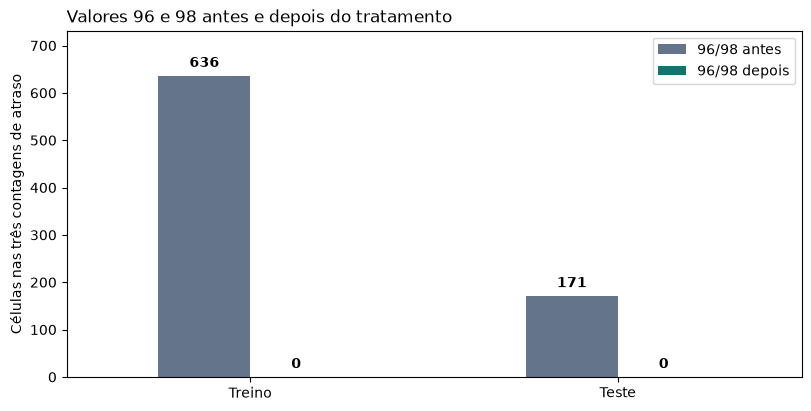

,96/98 antes,96/98 depois,Ausências depois
conjunto,,,
Treino,636,0,0
Teste,171,0,0


In [8]:
auditoria = []

for nome, origem, tratadas in [
    ("Treino", dados_treino, X_treino),
    ("Teste", dados_teste, X_teste),
]:
    auditoria.append({
        "conjunto": nome,
        "96/98 antes": origem[colunas_atraso].isin([96, 98]).sum().sum(),
        "96/98 depois": tratadas[colunas_atraso].isin([96, 98]).sum().sum(),
        "Ausências depois": tratadas[colunas_atraso].isna().sum().sum(),
    })

auditoria_atrasos = pd.DataFrame(auditoria).set_index("conjunto")

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")

auditoria_atrasos[["96/98 antes", "96/98 depois"]].plot.bar(
    ax=ax, color=["#64748b", "#0f766e"], rot=0
)
for barras in ax.containers:
    ax.bar_label(barras, padding=4, fontweight="bold")

ax.set_title("Valores 96 e 98 antes e depois do tratamento", loc="left")
ax.set_xlabel("")
ax.set_ylabel("Células nas três contagens de atraso")
ax.margins(y=0.15)

plt.show()
auditoria_atrasos

#### Resultado da verificação

O tratamento substituiu 807 valores sinalizados, distribuídos em 269 registros. As três contagens de atraso ficaram sem valores `96` ou `98` e sem lacunas no treino e no teste.

O valor `0` foi imputado a partir das medianas do treino. A coluna `tem_atraso_96_98` permite identificar os registros que receberam esse tratamento.

### Renda mensal por faixa etária e quantidade de créditos em aberto

Antes da imputação, vamos contar as rendas informadas e ausentes em cada combinação de faixa etária e faixa de créditos em aberto. A análise usa apenas o treino.

Renda igual a zero conta como valor informado nesta checagem. A imputação será aplicada aos registros em que `MonthlyIncome` está ausente.

In [9]:
limites_idade = [18, 30, 45, 60, 75, float("inf")]
rotulos_idade = ["18–29", "30–44", "45–59", "60–74", "75+"]

limites_credito = [0, 5, 10, 15, float("inf")]
rotulos_credito = ["0–4", "5–9", "10–14", "15+"]

grupos_renda_treino = X_treino.assign(
    faixa_idade=pd.cut(
        X_treino["age"], limites_idade, labels=rotulos_idade, right=False
    ),
    faixa_credito=pd.cut(
        X_treino["NumberOfOpenCreditLinesAndLoans"],
        limites_credito,
        labels=rotulos_credito,
        right=False,
    ),
)

resumo_grupos_renda = grupos_renda_treino.groupby(
    ["faixa_idade", "faixa_credito"], observed=True
)["MonthlyIncome"].agg(
    registros="size",
    rendas_informadas="count",
    mediana_renda="median",
)
resumo_grupos_renda["rendas_ausentes"] = (
    resumo_grupos_renda["registros"] - resumo_grupos_renda["rendas_informadas"]
)

resumo_grupos_renda[
    ["rendas_informadas", "rendas_ausentes"]
].unstack("faixa_credito")

rendas_informadas                     rendas_ausentes        \
faixa_credito               0–4    5–9  10–14   15+             0–4   5–9   
faixa_idade                                                                 
18–29                      3295   2035    437    76             848   248   
30–44                      6095  12991   5839  2016            1548  1858   
45–59                      5081  14560  10056  5597            2038  3380   
60–74                      3326   8909   6053  3761            1938  3244   
75+                        1451   2548   1422   711            1312  1164   

                          
faixa_credito 10–14  15+  
faixa_idade               
18–29            44    4  
30–44           671  197  
45–59          1663  746  
60–74          1544  781  
75+             365  149

#### Cobertura dos grupos para imputação de renda

A cor representa o percentual de rendas ausentes dentro de cada grupo. O número abaixo do percentual indica quantas rendas informadas estão disponíveis no treino para calcular a mediana do grupo.

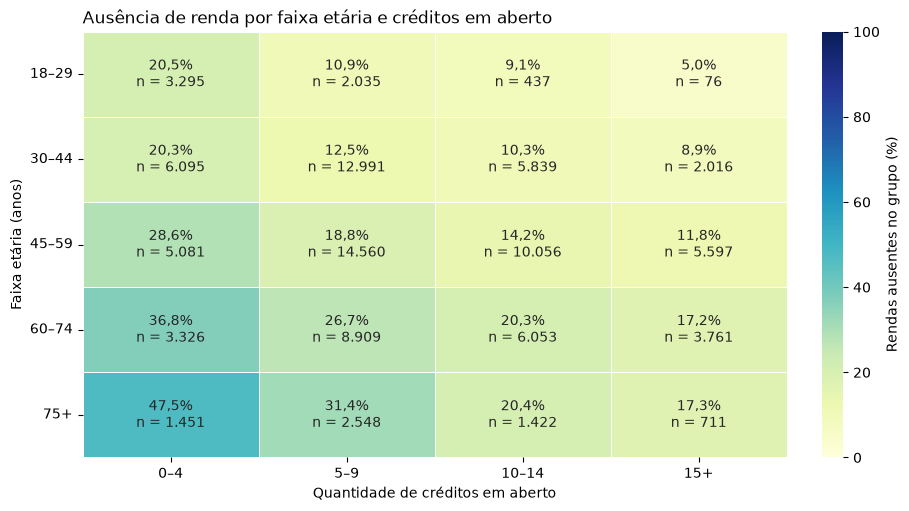

In [10]:
import seaborn as sns

rendas_informadas = resumo_grupos_renda["rendas_informadas"].unstack("faixa_credito")
taxa_ausencia_renda = (
    resumo_grupos_renda["rendas_ausentes"]
    .div(resumo_grupos_renda["registros"])
    .mul(100)
    .unstack("faixa_credito")
)

anotacoes = [
    [
        f"{taxa:.1f}%".replace(".", ",") + f"\nn = {quantidade:,.0f}".replace(",", ".")
        for taxa, quantidade in zip(linha_taxas, linha_contagens)
    ]
    for linha_taxas, linha_contagens in zip(
        taxa_ausencia_renda.to_numpy(), rendas_informadas.to_numpy()
    )
]

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")

sns.heatmap(
    taxa_ausencia_renda,
    annot=anotacoes,
    fmt="",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Rendas ausentes no grupo (%)"},
    ax=ax,
)

ax.set_title("Ausência de renda por faixa etária e créditos em aberto", loc="left")
ax.set_xlabel("Quantidade de créditos em aberto")
ax.set_ylabel("Faixa etária (anos)")
ax.tick_params(axis="y", labelrotation=0)

plt.show()

#### O que o mapa de calor mostra

Cada célula representa uma combinação de faixa etária e número de créditos em aberto no treino. A cor e o percentual mostram a proporção de rendas ausentes no grupo. O valor `n` indica quantas rendas informadas estão disponíveis para calcular a mediana.

| Grupo | Rendas ausentes | Rendas informadas (`n`) |
| --- | ---: | ---: |
| 18–29 anos e 15+ créditos em aberto | 4 de 80 (5,0%) | 76 |
| 75+ anos e 0–4 créditos em aberto | 1.312 de 2.763 (47,5%) | 1.451 |

O grupo de **18–29 anos com 15+ créditos** tem a menor quantidade de rendas informadas entre os grupos, mas só quatro registros precisam de preenchimento. Já o grupo de **75+ anos com 0–4 créditos** tem renda ausente em quase metade dos registros, mesmo contando com 1.451 valores informados.

Para a imputação, o percentual indica **quanto do grupo será afetado pelo preenchimento**. O `n` indica **quantas observações sustentam a mediana**. Uma mediana calculada com muitos registros ainda pode refletir diferenças entre quem informou a renda e quem deixou o campo vazio.

#### Imputação da renda pela mediana do grupo

Para cada renda ausente, procuramos a mediana do grupo definido pela faixa etária e pela quantidade de créditos em aberto. Se o grupo estiver sem uma mediana disponível, usamos a mediana global do treino.

As duas referências são calculadas apenas no treino. O indicador `is_income_missing` registra se a renda estava ausente no CSV. Os valores informados, inclusive zero, são preservados.

In [11]:
medianas_renda_por_grupo = resumo_grupos_renda["mediana_renda"]
mediana_renda_global = dados_treino["MonthlyIncome"].median()

auditoria_renda = []

for nome, origem, entradas in [
    ("Treino", dados_treino, X_treino),
    ("Teste", dados_teste, X_teste),
]:
    faixa_idade = pd.cut(
        entradas["age"], limites_idade, labels=rotulos_idade, right=False
    )
    faixa_credito = pd.cut(
        entradas["NumberOfOpenCreditLinesAndLoans"],
        limites_credito,
        labels=rotulos_credito,
        right=False,
    )
    chaves = pd.MultiIndex.from_arrays(
        [faixa_idade, faixa_credito],
        names=["faixa_idade", "faixa_credito"],
    )

    mediana_grupo = medianas_renda_por_grupo.reindex(chaves).set_axis(entradas.index)
    renda_original = origem["MonthlyIncome"]
    renda_ausente = renda_original.isna()

    entradas["is_income_missing"] = renda_ausente.astype("int8")
    entradas["MonthlyIncome"] = renda_original.fillna(
        mediana_grupo.fillna(mediana_renda_global)
    )

    auditoria_renda.append({
        "conjunto": nome,
        "ausentes_antes": renda_ausente.sum(),
        "preenchidas_pelo_grupo": (renda_ausente & mediana_grupo.notna()).sum(),
        "preenchidas_pela_global": (renda_ausente & mediana_grupo.isna()).sum(),
        "ausentes_depois": entradas["MonthlyIncome"].isna().sum(),
    })

pd.DataFrame(auditoria_renda).set_index("conjunto")

,ausentes_antes,preenchidas_pelo_grupo,preenchidas_pela_global,ausentes_depois
conjunto,,,,
Treino,23742,23742,0,0
Teste,5989,5989,0,0


#### Distribuição da renda após o preenchimento

Todas as 29.731 rendas ausentes foram preenchidas com a mediana do grupo. No gráfico, comparamos as rendas informadas com as imputadas no treino. Como cada grupo recebe uma única mediana, esperamos ver saltos na curva dos valores imputados.

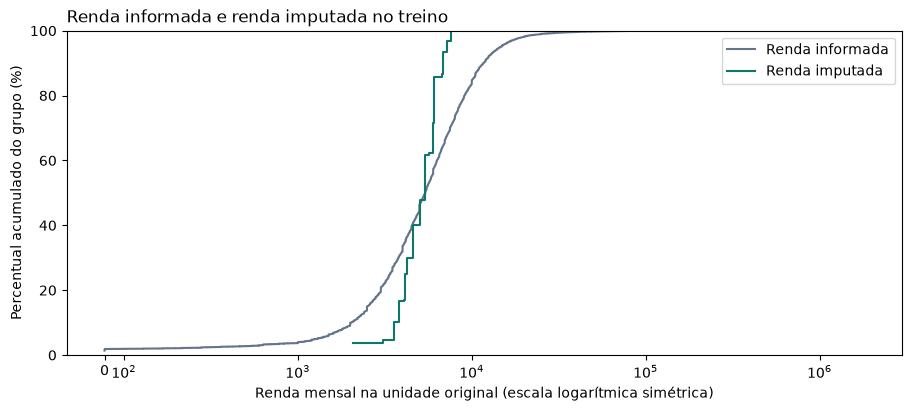

In [12]:
renda_imputada = X_treino["is_income_missing"].eq(1)

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")

for rotulo, filtro, cor in [
    ("Renda informada", ~renda_imputada, "#64748b"),
    ("Renda imputada", renda_imputada, "#0f766e"),
]:
    acumulado = (
        X_treino.loc[filtro, "MonthlyIncome"]
        .value_counts(normalize=True)
        .sort_index()
        .cumsum()
        .mul(100)
    )
    ax.step(acumulado.index, acumulado, where="post", label=rotulo, color=cor)

ax.set_xscale("symlog", linthresh=1_000)
ax.set_ylim(0, 100)
ax.set_xlabel("Renda mensal na unidade original (escala logarítmica simétrica)")
ax.set_ylabel("Percentual acumulado do grupo (%)")
ax.set_title("Renda informada e renda imputada no treino", loc="left")
ax.legend()

plt.show()

#### O que mudou na distribuição da renda

As rendas imputadas se concentram em alguns valores. Cada degrau da curva verde representa registros que receberam a mesma mediana. As rendas informadas apresentam uma distribuição mais espalhada, com uma cauda à direita.

Esse é um efeito esperado do preenchimento por mediana de grupo. Os valores imputados são estimativas, e `is_income_missing` permite identificar quais rendas foram preenchidas.

### Tratamento de valores ausentes em dependentes

Calculamos a mediana de `NumberOfDependents` com os valores informados no treino e usamos essa mesma referência para preencher as ausências no treino e no teste.

A coluna `is_dependents_missing` indica se a quantidade de dependentes estava ausente no CSV. Assim, se a mediana for zero, ainda será possível identificar quais zeros vieram do preenchimento.

In [13]:
mediana_dependentes = dados_treino["NumberOfDependents"].median()
print(f"Mediana de dependentes no treino: {mediana_dependentes:g}")

auditoria_dependentes = []

for nome, origem, entradas in [
    ("Treino", dados_treino, X_treino),
    ("Teste", dados_teste, X_teste),
]:
    dependentes_originais = origem["NumberOfDependents"]
    dependentes_ausentes = dependentes_originais.isna()

    entradas["is_dependents_missing"] = dependentes_ausentes.astype("int8")
    entradas["NumberOfDependents"] = dependentes_originais.fillna(mediana_dependentes)

    auditoria_dependentes.append({
        "conjunto": nome,
        "ausentes_antes": dependentes_ausentes.sum(),
        "ausentes_depois": entradas["NumberOfDependents"].isna().sum(),
    })

pd.DataFrame(auditoria_dependentes).set_index("conjunto")

Mediana de dependentes no treino: 0


,ausentes_antes,ausentes_depois
conjunto,,
Treino,3135,0
Teste,789,0


### Tratamento de DebtRatio quando a renda original é zero ou ausente

A definição de `DebtRatio` usa a renda mensal bruta no denominador. Nos casos de renda zero ou ausente, o cálculo original permanece incerto.

Para a primeira versão do pipeline, substituímos `DebtRatio` nesses casos pela mediana dos registros de treino com renda original positiva. Os indicadores `is_income_missing` e `is_income_zero` preservam a diferença entre as duas situações.

In [14]:
renda_positiva_treino = dados_treino["MonthlyIncome"].gt(0)
mediana_debt_ratio = dados_treino.loc[renda_positiva_treino, "DebtRatio"].median()
print(f"Mediana de DebtRatio no treino com renda positiva: {mediana_debt_ratio:.4f}")

auditoria_debt_ratio = []

for nome, origem, entradas in [
    ("Treino", dados_treino, X_treino),
    ("Teste", dados_teste, X_teste),
]:
    renda_original = origem["MonthlyIncome"]
    renda_zero = renda_original.eq(0)
    renda_ausente = renda_original.isna()
    substituir_ratio = renda_zero | renda_ausente

    entradas["is_income_zero"] = renda_zero.astype("int8")
    entradas["DebtRatio"] = origem["DebtRatio"].mask(
        substituir_ratio, mediana_debt_ratio
    )

    auditoria_debt_ratio.append({
        "conjunto": nome,
        "renda_zero": renda_zero.sum(),
        "renda_ausente": renda_ausente.sum(),
        "registros_com_debtratio_imputado": substituir_ratio.sum(),
    })

pd.DataFrame(auditoria_debt_ratio).set_index("conjunto")

Mediana de DebtRatio no treino com renda positiva: 0.2924


,renda_zero,renda_ausente,registros_com_debtratio_imputado
conjunto,,,
Treino,1310,23742,25052
Teste,324,5989,6313


#### Verificação do tratamento de DebtRatio

Comparamos as medianas de `DebtRatio` antes e depois do tratamento no treino, separando renda igual a zero de renda ausente. Os dois grupos passam a ter a mesma mediana porque usamos o mesmo valor de referência no preenchimento.

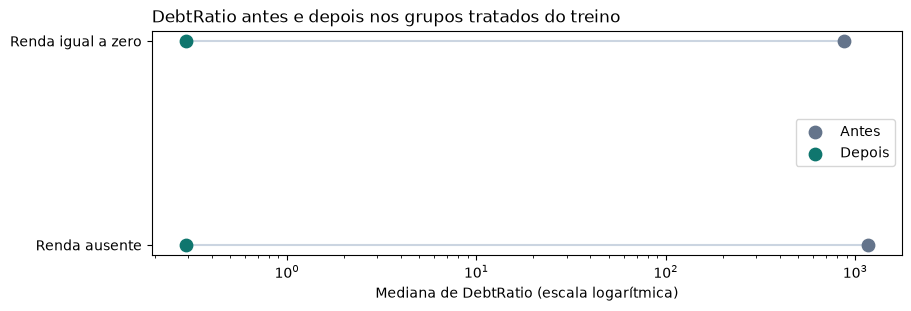

,Antes,Depois
Renda igual a zero,869.0,0.2924
Renda ausente,1161.0,0.2924


In [15]:
renda_original_treino = dados_treino["MonthlyIncome"]

grupos_debt_ratio = {
    "Renda igual a zero": renda_original_treino.eq(0),
    "Renda ausente": renda_original_treino.isna(),
}

comparacao_debt_ratio = pd.DataFrame.from_dict(
    {
        grupo: {
            "Antes": dados_treino.loc[filtro, "DebtRatio"].median(),
            "Depois": X_treino.loc[filtro, "DebtRatio"].median(),
        }
        for grupo, filtro in grupos_debt_ratio.items()
    },
    orient="index",
)

fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")

ax.hlines(
    y=comparacao_debt_ratio.index,
    xmin=comparacao_debt_ratio["Depois"],
    xmax=comparacao_debt_ratio["Antes"],
    color="#cbd5e1",
)
ax.scatter(
    comparacao_debt_ratio["Antes"], comparacao_debt_ratio.index,
    color="#64748b", s=80, label="Antes", zorder=3,
)
ax.scatter(
    comparacao_debt_ratio["Depois"], comparacao_debt_ratio.index,
    color="#0f766e", s=80, label="Depois", zorder=3,
)

ax.set_xscale("log")
ax.set_xlabel("Mediana de DebtRatio (escala logarítmica)")
ax.set_title("DebtRatio antes e depois nos grupos tratados do treino", loc="left")
ax.invert_yaxis()
ax.legend()

plt.show()
comparacao_debt_ratio.round(4)

#### Resultado do tratamento de DebtRatio

No treino, as medianas originais de `DebtRatio` eram 869 para renda zero e 1.161 para renda ausente. Após o tratamento, ambas passaram a 0,2924, a mediana calculada nos registros de treino com renda original positiva.

O preenchimento substitui a variação original de `DebtRatio` nesses dois grupos por um valor comum. Os indicadores `is_income_zero` e `is_income_missing` permitem distinguir as duas situações durante a modelagem. O efeito dessa decisão será medido na comparação entre o modelo de referência e o pipeline tratado.

### Limitação dos valores extremos no uso de crédito

Na EDA, a utilização do limite chegou a 50.708 na unidade original da coluna. Para reduzir a influência desses extremos, calculamos o percentil 99 de `RevolvingUtilizationOfUnsecuredLines` no treino.

Valores acima desse teto são substituídos pelo próprio teto no treino e no teste. Os demais valores são preservados. Essa técnica é chamada de winsorização unilateral.

In [16]:
coluna_utilizacao = "RevolvingUtilizationOfUnsecuredLines"
teto_utilizacao = dados_treino[coluna_utilizacao].quantile(0.99)

print(f"Teto calculado no treino (P99): {teto_utilizacao:.6f}")

auditoria_utilizacao = []

for nome, origem, entradas in [
    ("Treino", dados_treino, X_treino),
    ("Teste", dados_teste, X_teste),
]:
    valores_originais = origem[coluna_utilizacao]
    valores_tratados = valores_originais.clip(upper=teto_utilizacao)
    entradas[coluna_utilizacao] = valores_tratados

    auditoria_utilizacao.append({
        "conjunto": nome,
        "registros_limitados": valores_originais.gt(teto_utilizacao).sum(),
        "maximo_antes": valores_originais.max(),
        "maximo_depois": valores_tratados.max(),
    })

pd.DataFrame(auditoria_utilizacao).set_index("conjunto").round(6)

Teto calculado no treino (P99): 1.096866


,registros_limitados,maximo_antes,maximo_depois
conjunto,,,
Treino,1200,50708.0,1.096866
Teste,271,13930.0,1.096866


#### Efeito do teto na cauda da distribuição

O teto calculado no treino foi `1,096866`. O tratamento afetou 1.200 registros no treino e 271 no teste.

O gráfico compara os percentis 98 a 100 do treino antes e depois do tratamento. A linha tracejada marca o percentil 99, e o trecho horizontal da curva tratada mostra onde os valores foram limitados.

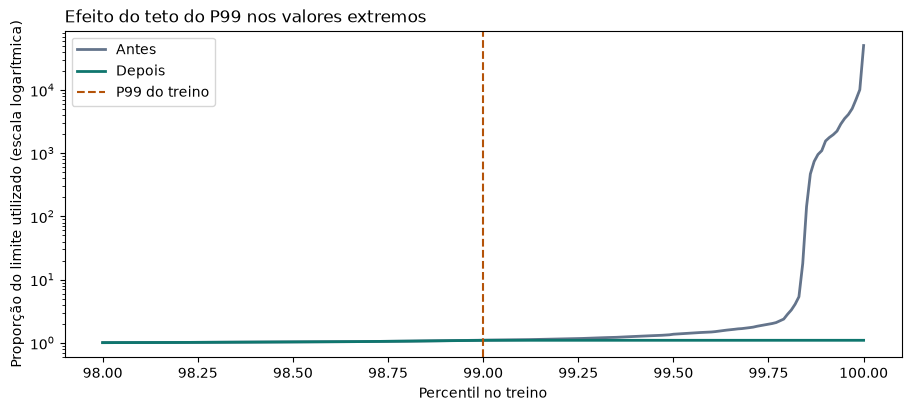

In [17]:
import numpy as np

quantis = np.linspace(0.98, 1.0, 201)
antes = dados_treino[coluna_utilizacao].quantile(quantis)
depois = X_treino[coluna_utilizacao].quantile(quantis)

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")

ax.plot(quantis * 100, antes, color="#64748b", linewidth=2, label="Antes")
ax.plot(quantis * 100, depois, color="#0f766e", linewidth=2, label="Depois")
ax.axvline(99, color="#b45309", linestyle="--", label="P99 do treino")

ax.set_yscale("log")
ax.set_xlabel("Percentil no treino")
ax.set_ylabel("Proporção do limite utilizado (escala logarítmica)")
ax.set_title("Efeito do teto do P99 nos valores extremos", loc="left")
ax.legend()

plt.show()

## Engenharia de variáveis

### Histórico consolidado de atrasos

`TotalPastDue` soma as contagens tratadas de atraso de 30 a 59 dias, 60 a 89 dias e 90 dias ou mais.

`HasSevereDelinquencyHistory` vale `1` quando a contagem tratada de atrasos de 90 dias ou mais é positiva, e `0` nos demais casos. O indicador `tem_atraso_96_98` continua disponível para identificar os registros cujas contagens foram imputadas.

In [18]:
resumo_historico = []

for nome, entradas in [("Treino", X_treino), ("Teste", X_teste)]:
    entradas["TotalPastDue"] = entradas[colunas_atraso].sum(axis=1)
    entradas["HasSevereDelinquencyHistory"] = (
        entradas["NumberOfTimes90DaysLate"].gt(0).astype("int8")
    )

    resumo_historico.append({
        "conjunto": nome,
        "registros_com_algum_atraso": entradas["TotalPastDue"].gt(0).sum(),
        "registros_com_atraso_grave_no_historico": (
            entradas["HasSevereDelinquencyHistory"].sum()
        ),
    })

pd.DataFrame(resumo_historico).set_index("conjunto")

,registros_com_algum_atraso,registros_com_atraso_grave_no_historico
conjunto,,
Treino,24047,6474
Teste,6047,1595


## Validação da base tratada

O Clean Gate verifica as 16 variáveis de entrada do modelo após a limpeza. Todas devem estar presentes e preenchidas. O contrato também verifica a idade mínima, as contagens não negativas, a ausência de `96` e `98` no histórico de atrasos e o domínio `0` ou `1` dos indicadores.

A validação é aplicada separadamente ao treino e ao teste.

In [19]:
from src.schema_validator import CLEAN_SCHEMA

for nome, entradas in [("Treino", X_treino), ("Teste", X_teste)]:
    CLEAN_SCHEMA.validate(entradas, lazy=True)
    print(f"{nome}: Clean Gate aprovado em {len(entradas)} registros.")

Treino: Clean Gate aprovado em 120001 registros.
Teste: Clean Gate aprovado em 29999 registros.


## Comparação de escalonamento

O `StandardScaler` usa a média e o desvio padrão. O `RobustScaler` usa a mediana e o intervalo interquartil (distância entre P25 e P75).

Ajustamos os dois métodos apenas no treino e comparamos o centro e a dispersão dos valores transformados de `DebtRatio`. O boxplot destaca a faixa central da distribuição. Os valores extremos ficam ocultos no gráfico e entram no ajuste dos escalonadores.

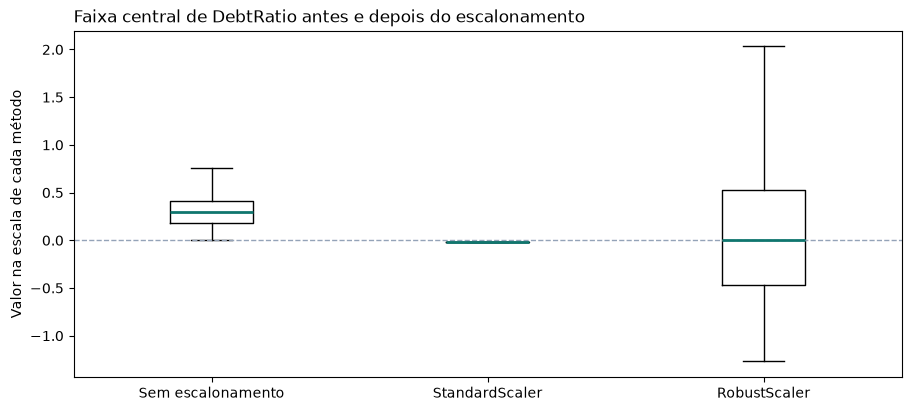

,P25,Mediana,P75,IQR
Sem escalonamento,0.1844,0.2924,0.4152,0.2308
StandardScaler,-0.0221,-0.0215,-0.0209,0.0012
RobustScaler,-0.4679,0.0000,0.5321,1.0000


In [20]:
from sklearn.preprocessing import RobustScaler, StandardScaler

debt_ratio_treino = X_treino[["DebtRatio"]]

comparacao_escalas = pd.DataFrame({
    "Sem escalonamento": debt_ratio_treino["DebtRatio"],
    "StandardScaler": StandardScaler().fit_transform(debt_ratio_treino).ravel(),
    "RobustScaler": RobustScaler().fit_transform(debt_ratio_treino).ravel(),
}, index=X_treino.index)

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")

ax.boxplot(
    [comparacao_escalas[coluna] for coluna in comparacao_escalas],
    showfliers=False,
    medianprops={"color": "#0f766e", "linewidth": 2},
)
ax.set_xticks([1, 2, 3], comparacao_escalas.columns)
ax.axhline(0, color="#94a3b8", linestyle="--", linewidth=1)
ax.set_ylabel("Valor na escala de cada método")
ax.set_title("Faixa central de DebtRatio antes e depois do escalonamento", loc="left")

plt.show()

resumo_escalas = comparacao_escalas.quantile([0.25, 0.50, 0.75]).T
resumo_escalas.columns = ["P25", "Mediana", "P75"]
resumo_escalas["IQR"] = resumo_escalas["P75"] - resumo_escalas["P25"]
resumo_escalas.round(4)

### Escolha do escalonador para a regressão logística

No treino, a faixa central de `DebtRatio` ficou comprimida após o `StandardScaler`, com IQR de 0,0012. O `RobustScaler` centralizou a mediana em 0 e colocou o intervalo entre P25 e P75 em uma escala de uma unidade.

Vamos usar `RobustScaler` nas duas versões da regressão logística, ajustado separadamente no treino de cada abordagem. Assim, a comparação usa o mesmo método de escalonamento. O desempenho será avaliado nos mesmos registros elegíveis do conjunto de teste.

## Protocolo de comparação dos modelos

A abordagem de referência usa as variáveis brutas e seleciona as linhas completas com `dropna()` no treino e no teste. O pipeline tratado usa todo o treino após a limpeza.

Para comparar as métricas, as duas abordagens serão avaliadas nos mesmos registros de teste, na mesma ordem e com os mesmos rótulos. A cobertura do teste será reportada separadamente.

In [21]:
colunas_entrada = entradas_brutas.columns

X_treino_referencia = dados_treino[colunas_entrada].dropna()
X_teste_referencia = dados_teste[colunas_entrada].dropna()

indices_teste_comum = X_teste_referencia.index
X_teste_tratado_comum = X_teste.loc[indices_teste_comum]

y_treino_referencia = alvo.loc[X_treino_referencia.index]
y_treino_tratado = alvo.loc[X_treino.index]
y_teste_comum = alvo.loc[indices_teste_comum]

assert X_teste_referencia.index.equals(X_teste_tratado_comum.index)
assert X_teste_referencia.index.equals(y_teste_comum.index)

total_teste = len(X_teste)
total_comum = len(indices_teste_comum)

cobertura_teste = pd.DataFrame(
    {"registros": [total_comum, total_teste - total_comum]},
    index=["Na comparação direta", "Fora da comparação direta"],
)
cobertura_teste["percentual_do_teste"] = (
    cobertura_teste["registros"] / total_teste * 100
).round(2)

cobertura_teste

,registros,percentual_do_teste
Na comparação direta,24010,80.04
Fora da comparação direta,5989,19.96


### Treinamento da regressão logística

Treinamos duas regressões logísticas com a mesma configuração. A referência usa as linhas completas e as dez variáveis brutas. O pipeline tratado usa todo o treino, com os valores tratados e as variáveis derivadas.

Cada modelo ajusta seu próprio `RobustScaler` com os dados de treino que recebe. A comparação mede o efeito conjunto dessas decisões de preparação.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

logistica_referencia = make_pipeline(
    RobustScaler(),
    LogisticRegression(max_iter=2_000),
)
logistica_tratada = make_pipeline(
    RobustScaler(),
    LogisticRegression(max_iter=2_000),
)

logistica_referencia.fit(X_treino_referencia, y_treino_referencia)
logistica_tratada.fit(X_treino, y_treino_tratado)

prob_referencia = logistica_referencia.predict_proba(X_teste_referencia)[:, 1]
prob_tratada = logistica_tratada.predict_proba(X_teste_tratado_comum)[:, 1]

pd.DataFrame(
    {
        "registros_de_treino": [len(X_treino_referencia), len(X_treino)],
        "probabilidades_no_teste": [len(prob_referencia), len(prob_tratada)],
    },
    index=["Referência", "Pipeline tratado"],
)

,registros_de_treino,probabilidades_no_teste
Referência,96259,24010
Pipeline tratado,120001,24010


### Métricas da regressão logística no teste comum

A ROC-AUC mede a capacidade de ranquear os casos de atraso grave acima dos demais. O KS mede a maior separação entre as distribuições dos escores das duas classes.

O recall mede a proporção dos casos reais de atraso grave que o modelo identificou com o limiar de 0,50. Esse limiar também será usado nas matrizes de confusão.

In [23]:
from sklearn.metrics import recall_score, roc_auc_score, roc_curve

limiar_logistica = 0.50
probabilidades_logistica = {
    "Referência": prob_referencia,
    "Pipeline tratado": prob_tratada,
}

previsoes_logistica = {}
resultados_logistica = []

for nome, probabilidades in probabilidades_logistica.items():
    previsoes = (probabilidades >= limiar_logistica).astype(int)
    previsoes_logistica[nome] = previsoes

    taxa_falsos_positivos, taxa_verdadeiros_positivos, _ = roc_curve(
        y_teste_comum, probabilidades
    )

    resultados_logistica.append({
        "abordagem": nome,
        "ROC-AUC": roc_auc_score(y_teste_comum, probabilidades),
        "KS": np.abs(taxa_verdadeiros_positivos - taxa_falsos_positivos).max(),
        "recall_classe_1": recall_score(y_teste_comum, previsoes),
        "previstos_com_atraso_grave": previsoes.sum(),
    })

pd.DataFrame(resultados_logistica).set_index("abordagem").round(4)

,ROC-AUC,KS,recall_classe_1,previstos_com_atraso_grave
abordagem,,,,
Referência,0.6853,0.3035,0.0354,101
Pipeline tratado,0.8384,0.5230,0.1838,541


### Matrizes de confusão da regressão logística

As duas matrizes usam os mesmos 24.010 registros de teste e o limiar de 0,50. As linhas mostram a classe real e as colunas mostram a previsão.

Cada célula exibe a contagem e o percentual dentro da sua classe real. A célula inferior direita mostra o recall da classe de atraso grave. A inferior esquerda mostra a proporção de casos graves que passaram sem sinalização.

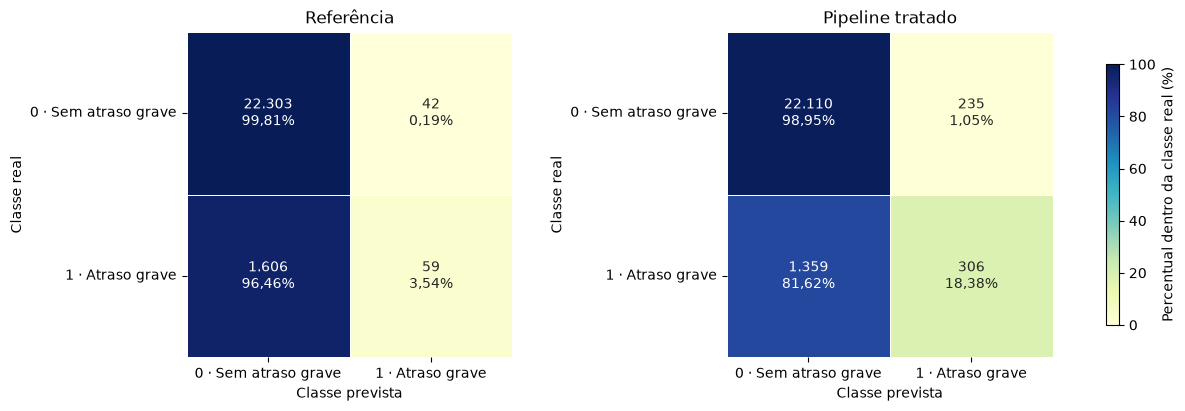

In [24]:
from sklearn.metrics import confusion_matrix

rotulos_classes = ["0 · Sem atraso grave", "1 · Atraso grave"]

fig, eixos = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for ax, (nome, previsoes) in zip(eixos, previsoes_logistica.items()):
    contagens = confusion_matrix(y_teste_comum, previsoes, labels=[0, 1])
    percentuais = contagens / contagens.sum(axis=1, keepdims=True) * 100

    anotacoes = [
        [
            f"{contagem:,}".replace(",", ".")
            + "\n"
            + f"{percentual:.2f}%".replace(".", ",")
            for contagem, percentual in zip(linha_contagens, linha_percentuais)
        ]
        for linha_contagens, linha_percentuais in zip(contagens, percentuais)
    ]

    sns.heatmap(
        percentuais,
        annot=anotacoes,
        fmt="",
        cmap="YlGnBu",
        vmin=0,
        vmax=100,
        square=True,
        linewidths=0.5,
        cbar=False,
        xticklabels=rotulos_classes,
        yticklabels=rotulos_classes,
        ax=ax,
    )
    ax.set_title(nome)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.tick_params(axis="y", labelrotation=0)

fig.colorbar(
    eixos[0].collections[0],
    ax=eixos,
    label="Percentual dentro da classe real (%)",
    shrink=0.8,
)

plt.show()

#### Interpretação das matrizes de confusão

Com o limiar de 0,50, o pipeline tratado identificou 306 dos 1.665 casos reais de atraso grave, ante 59 na referência. O recall subiu de 3,54% para 18,38%.

A taxa de falsos alarmes entre os registros sem atraso grave passou de 0,19% (42 casos) para 1,05% (235 casos). O pipeline tratado detectou mais casos graves e ainda deixou 1.359 sem sinalização, ou 81,62% da classe `1`.

Esses resultados descrevem a comparação no limiar de 0,50 e nos 24.010 registros elegíveis para as duas abordagens.

### Comparação com Random Forest

Treinamos duas Random Forests com 150 árvores, no mínimo cinco registros por folha e semente 42. A referência usa as linhas completas do treino bruto. O pipeline tratado usa todo o treino após a preparação.

A avaliação usa os mesmos 24.010 registros da regressão logística. Calculamos ROC-AUC, KS e recall da classe `1` com limiar de 0,50.

In [25]:
from sklearn.ensemble import RandomForestClassifier

abordagens_floresta = [
    ("Referência", X_treino_referencia, y_treino_referencia, X_teste_referencia),
    ("Pipeline tratado", X_treino, y_treino_tratado, X_teste_tratado_comum),
]

modelos_floresta = {}
probabilidades_floresta = {}
previsoes_floresta = {}
resultados_floresta = []

for nome, X_ajuste, y_ajuste, X_avaliacao in abordagens_floresta:
    modelo = RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    )
    modelo.fit(X_ajuste, y_ajuste)

    probabilidades = modelo.predict_proba(X_avaliacao)[:, 1]
    previsoes = (probabilidades >= limiar_logistica).astype(int)
    fpr, tpr, _ = roc_curve(y_teste_comum, probabilidades)

    modelos_floresta[nome] = modelo
    probabilidades_floresta[nome] = probabilidades
    previsoes_floresta[nome] = previsoes

    resultados_floresta.append({
        "abordagem": nome,
        "ROC-AUC": roc_auc_score(y_teste_comum, probabilidades),
        "KS": np.abs(tpr - fpr).max(),
        "recall_classe_1": recall_score(y_teste_comum, previsoes),
        "previstos_com_atraso_grave": previsoes.sum(),
    })

pd.DataFrame(resultados_floresta).set_index("abordagem").round(4)

,ROC-AUC,KS,recall_classe_1,previstos_com_atraso_grave
abordagem,,,,
Referência,0.8389,0.5366,0.1610,452
Pipeline tratado,0.8388,0.5381,0.1724,487


### Comparação visual das curvas ROC

Cada painel compara a referência com o pipeline tratado para um algoritmo. As curvas mostram a taxa de detecção de atrasos graves e a taxa de falsos alarmes ao variar o limiar.

Na regressão logística, a ROC-AUC passou de 0,6853 para 0,8384. Na Random Forest, as duas abordagens obtiveram ROC-AUC próxima de 0,839. Todos os resultados usam os mesmos 24.010 registros de teste.

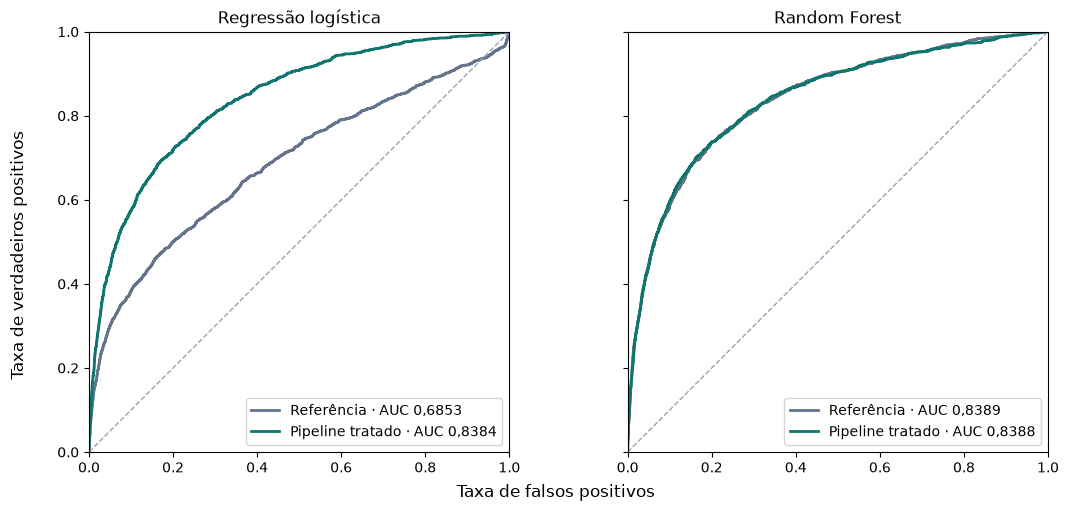

In [26]:
fig, eixos = plt.subplots(
    1, 2, figsize=(11, 5), sharex=True, sharey=True, layout="constrained"
)

comparacoes_roc = [
    ("Regressão logística", probabilidades_logistica),
    ("Random Forest", probabilidades_floresta),
]

cores = {"Referência": "#64748b", "Pipeline tratado": "#0f766e"}

for ax, (algoritmo, probabilidades_por_abordagem) in zip(eixos, comparacoes_roc):
    for abordagem, probabilidades in probabilidades_por_abordagem.items():
        fpr, tpr, _ = roc_curve(y_teste_comum, probabilidades)
        auc = roc_auc_score(y_teste_comum, probabilidades)
        rotulo = f"{abordagem} · AUC {auc:.4f}".replace(".", ",")

        ax.plot(fpr, tpr, color=cores[abordagem], linewidth=2, label=rotulo)

    ax.plot([0, 1], [0, 1], color="#94a3b8", linestyle="--", linewidth=1)
    ax.set_title(algoritmo)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal", adjustable="box")
    ax.legend(loc="lower right")

fig.supxlabel("Taxa de falsos positivos")
fig.supylabel("Taxa de verdadeiros positivos")

plt.show()

### Desempenho nos registros com campos originalmente ausentes

O teste contém 5.989 registros que a referência com `dropna()` não consegue avaliar. Neste recorte, medimos o desempenho das duas versões tratadas e mantemos o limiar de 0,50 para o cálculo do recall.

In [27]:
indices_teste_adicional = X_teste.index.difference(indices_teste_comum, sort=False)
X_teste_adicional = X_teste.loc[indices_teste_adicional]
y_teste_adicional = alvo.loc[indices_teste_adicional]

resultados_cobertura = []

for nome, modelo in [
    ("Regressão logística", logistica_tratada),
    ("Random Forest", modelos_floresta["Pipeline tratado"]),
]:
    probabilidades = modelo.predict_proba(X_teste_adicional)[:, 1]
    previsoes = (probabilidades >= limiar_logistica).astype(int)
    fpr, tpr, _ = roc_curve(y_teste_adicional, probabilidades)

    resultados_cobertura.append({
        "modelo": nome,
        "registros": len(y_teste_adicional),
        "casos_graves_reais": y_teste_adicional.sum(),
        "ROC-AUC": roc_auc_score(y_teste_adicional, probabilidades),
        "KS": np.abs(tpr - fpr).max(),
        "recall_classe_1": recall_score(y_teste_adicional, previsoes),
    })

pd.DataFrame(resultados_cobertura).set_index("modelo").round(4)

,registros,casos_graves_reais,ROC-AUC,KS,recall_classe_1
modelo,,,,,
Regressão logística,5989,340,0.8892,0.6454,0.1735
Random Forest,5989,340,0.8869,0.6475,0.2529


#### O que a cobertura adicional trouxe

| Modelo tratado | Casos graves detectados | Recall | ROC-AUC |
| --- | ---: | ---: | ---: |
| Regressão logística | 59 de 340 | 17,35% | 0,8892 |
| Random Forest | 86 de 340 | 25,29% | 0,8869 |

Neste subconjunto, os modelos tiveram ROC-AUC próxima. Com o limiar de 0,50, a Random Forest detectou 27 casos graves a mais. O resultado complementa a comparação direta nos 24.010 registros completos e mostra o desempenho nos casos que ficaram fora dela.

## Exportação dos resultados para o painel

Exportamos as métricas e a cobertura em `data/processed/`. A coluna `recorte` identifica se o resultado veio dos 24.010 registros da comparação direta ou dos 5.989 registros adicionais. Os arquivos contêm apenas resultados agregados.

In [28]:
pasta_saida = raiz_projeto / "data" / "processed"
pasta_saida.mkdir(parents=True, exist_ok=True)

metricas_logistica = pd.DataFrame(resultados_logistica).assign(
    modelo="Regressão logística"
)
metricas_floresta = pd.DataFrame(resultados_floresta).assign(
    modelo="Random Forest"
)

metricas_teste_comum = pd.concat(
    [metricas_logistica, metricas_floresta], ignore_index=True
).assign(
    recorte="Teste comum",
    registros=len(y_teste_comum),
    casos_graves_reais=y_teste_comum.sum(),
)

metricas_teste_adicional = pd.DataFrame(resultados_cobertura).assign(
    abordagem="Pipeline tratado",
    recorte="Teste adicional",
)

colunas_painel = [
    "recorte", "modelo", "abordagem", "registros", "casos_graves_reais",
    "ROC-AUC", "KS", "recall_classe_1",
]
metricas_painel = pd.concat(
    [metricas_teste_comum, metricas_teste_adicional], ignore_index=True
)[colunas_painel]

cobertura_painel = cobertura_teste.rename_axis("recorte").reset_index()

metricas_painel.to_csv(pasta_saida / "metricas_modelos.csv", index=False)
cobertura_painel.to_csv(pasta_saida / "cobertura_teste.csv", index=False)

print(f"Métricas exportadas: {len(metricas_painel)} linhas")
print(f"Cobertura exportada: {len(cobertura_painel)} linhas")

Métricas exportadas: 6 linhas
Cobertura exportada: 2 linhas


### Dados dos gráficos de avaliação

Exportamos os pontos das curvas ROC e as contagens das matrizes de confusão para as quatro combinações de algoritmo e abordagem. Nas matrizes, cada célula contém uma contagem e seu percentual dentro da classe real.

In [29]:
avaliacoes_painel = [
    ("Regressão logística", probabilidades_logistica, previsoes_logistica),
    ("Random Forest", probabilidades_floresta, previsoes_floresta),
]

curvas_roc = []
celulas_confusao = []

for modelo, probabilidades, previsoes in avaliacoes_painel:
    for abordagem, escores in probabilidades.items():
        fpr, tpr, _ = roc_curve(y_teste_comum, escores)

        curvas_roc.append(pd.DataFrame({
            "modelo": modelo,
            "abordagem": abordagem,
            "taxa_falsos_positivos": fpr,
            "taxa_verdadeiros_positivos": tpr,
        }))

        contagens = confusion_matrix(
            y_teste_comum, previsoes[abordagem], labels=[0, 1]
        )
        percentuais = contagens / contagens.sum(axis=1, keepdims=True) * 100

        for classe_real in (0, 1):
            for classe_prevista in (0, 1):
                celulas_confusao.append({
                    "modelo": modelo,
                    "abordagem": abordagem,
                    "classe_real": classe_real,
                    "classe_prevista": classe_prevista,
                    "registros": contagens[classe_real, classe_prevista],
                    "percentual_na_classe_real": percentuais[classe_real, classe_prevista],
                })

roc_painel = pd.concat(curvas_roc, ignore_index=True)
confusao_painel = pd.DataFrame(celulas_confusao)

roc_painel.to_csv(pasta_saida / "curvas_roc.csv", index=False)
confusao_painel.to_csv(pasta_saida / "matrizes_confusao.csv", index=False)

print(f"Curvas ROC exportadas: {len(curvas_roc)} curvas")
print(f"Matrizes de confusão exportadas: {len(confusao_painel)} células")

Curvas ROC exportadas: 4 curvas
Matrizes de confusão exportadas: 16 células


In [30]:
curva_utilizacao = pd.DataFrame({
    "percentil": quantis * 100,
    "Antes": dados_treino[coluna_utilizacao].quantile(quantis).to_numpy(),
    "Depois": X_treino[coluna_utilizacao].quantile(quantis).to_numpy(),
}).melt(
    id_vars="percentil",
    var_name="etapa",
    value_name="uso_do_limite",
)

curva_utilizacao.to_csv(pasta_saida / "efeito_teto_utilizacao.csv", index=False)
print(f"Pontos exportados: {len(curva_utilizacao)}")

Pontos exportados: 402


In [31]:
from pandera.errors import SchemaErrors

contratos = [
    ("Raw Gate", "Base original", RAW_SCHEMA, dados_brutos),
    ("Clean Gate", "Treino tratado", CLEAN_SCHEMA, X_treino),
    ("Clean Gate", "Teste tratado", CLEAN_SCHEMA, X_teste),
]

resultados_contratos = []

for contrato, conjunto, esquema, dados in contratos:
    try:
        esquema.validate(dados, lazy=True)
    except SchemaErrors as erro:
        resultado = "Reprovado"
        ocorrencias = len(erro.failure_cases)
    else:
        resultado = "Aprovado"
        ocorrencias = 0

    resultados_contratos.append({
        "Contrato": contrato,
        "Conjunto": conjunto,
        "Registros verificados": len(dados),
        "Resultado": resultado,
        "Ocorrências reportadas": ocorrencias,
    })

relatorio_contratos = pd.DataFrame(resultados_contratos)
relatorio_contratos.to_csv(pasta_saida / "validacoes_pandera.csv", index=False)
relatorio_contratos

,Contrato,Conjunto,Registros verificados,Resultado,Ocorrências reportadas
0,Raw Gate,Base original,150000,Aprovado,0
1,Clean Gate,Treino tratado,120001,Aprovado,0
2,Clean Gate,Teste tratado,29999,Aprovado,0
